# Oxygen Shake Strategy Backtests

This notebook evaluates two simple strategies for Oxygen Shake products:

- A naive market-making simulator that captures trades at best bid/ask when they occur.
- A lead-follower (pairs) strategy that uses detected leader signals to trade a follower product.

The notebook also computes liquidity and spread statistics, and summarizes comparative results.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from glob import glob
import warnings
warnings.filterwarnings('ignore')

# Paths
round_5_dir = r'c:\Users\soroc\Downloads\imc-prosperity-4\ROUND_5'
prices_files = sorted(glob(os.path.join(round_5_dir, 'prices_round_5_day_*.csv')))
trades_files = sorted(glob(os.path.join(round_5_dir, 'trades_round_5_day_*.csv')))

print(f"Found {len(prices_files)} prices files and {len(trades_files)} trades files")

# Load prices
prices_dfs = []
for file in prices_files:
    day = int(os.path.basename(file).split('_day_')[-1].split('.')[0])
    df = pd.read_csv(file, sep=';')
    df['day'] = day
    prices_dfs.append(df)
prices_df = pd.concat(prices_dfs, ignore_index=True)

# Load trades
trades_dfs = []
for file in trades_files:
    # Try to infer day from filename; if not present, set to 0
    day = int(os.path.basename(file).split('_day_')[-1].split('.')[0])
    df = pd.read_csv(file, sep=';')
    df['day'] = day
    trades_dfs.append(df)
trades_df = pd.concat(trades_dfs, ignore_index=True)

# Filter Oxygen Shake
prices_os = prices_df[prices_df['product'].str.contains('OXYGEN_SHAKE', case=False, na=False)].copy()
trades_os = trades_df[trades_df['symbol'].str.contains('OXYGEN_SHAKE', case=False, na=False)].copy()

# Prepare keys and time ordering
prices_os['time_idx'] = prices_os['day'] * 100000 + prices_os['timestamp']
prices_os.sort_values(['product', 'time_idx'], inplace=True)
trades_os['time_idx'] = trades_os['timestamp']  # trades may not have day in all files; rely on timestamp + day if present
if 'day' in trades_os.columns:
    trades_os['time_idx'] = trades_os['day'] * 100000 + trades_os['timestamp']

print(f"Loaded Oxygen Shake prices: {prices_os.shape}, trades: {trades_os.shape}")

Found 3 prices files and 3 trades files
Loaded Oxygen Shake prices: (150000, 18), trades: (3665, 9)


## Liquidity and Spread Evaluation

                             mid_price_mean  spread_mean  spread_median  \
product                                                                   
OXYGEN_SHAKE_CHOCOLATE          9556.879133    12.185467           12.0   
OXYGEN_SHAKE_EVENING_BREATH     9271.895000    11.860467           12.0   
OXYGEN_SHAKE_GARLIC            11925.639767    15.054600           15.0   
OXYGEN_SHAKE_MINT               9838.394083    12.593567           13.0   
OXYGEN_SHAKE_MORNING_BREATH    10000.453350    12.782900           13.0   

                             depth_mean  snapshots  
product                                             
OXYGEN_SHAKE_CHOCOLATE          36.5128      30000  
OXYGEN_SHAKE_EVENING_BREATH     36.5128      30000  
OXYGEN_SHAKE_GARLIC             36.5128      30000  
OXYGEN_SHAKE_MINT               36.5128      30000  
OXYGEN_SHAKE_MORNING_BREATH     36.5128      30000  


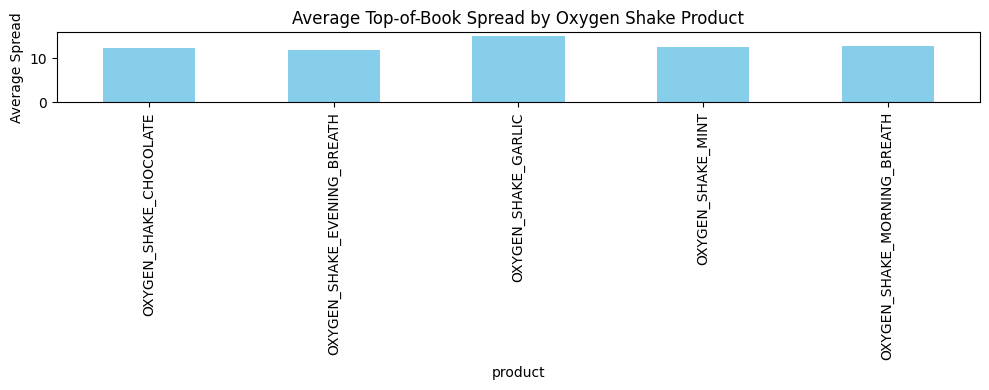

In [9]:
# Compute spread and depth stats per product
prices_os['spread'] = prices_os['ask_price_1'] - prices_os['bid_price_1']
prices_os['depth'] = prices_os['bid_volume_1'] + prices_os['ask_volume_1']

liquidity_stats = prices_os.groupby('product').agg(
    mid_price_mean=('mid_price', 'mean'),
    spread_mean=('spread', 'mean'),
    spread_median=('spread', 'median'),
    depth_mean=('depth', 'mean'),
    snapshots=('time_idx', 'count')
).sort_values('snapshots', ascending=False)

print(liquidity_stats)

# Plot spreads for top products
top_products = liquidity_stats.head(6).index.tolist()
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
liquidity_stats.loc[top_products, 'spread_mean'].plot(kind='bar', ax=ax, color='skyblue')
ax.set_title('Average Top-of-Book Spread by Oxygen Shake Product')
ax.set_ylabel('Average Spread')
plt.tight_layout()
plt.show()

## Market-Making Backtest (Naive Execution at Top-of-Book)

In [10]:
# Merge trades with corresponding price snapshot to check if trades hit top-of-book
merged = trades_os.merge(prices_os, how='left', left_on=['day','timestamp','symbol'], right_on=['day','timestamp','product'], suffixes=('_trade','_price'))


## Pairs / Lead-Follower Backtest

Top pair: OXYGEN_SHAKE_CHOCOLATE vs OXYGEN_SHAKE_GARLIC (corr=0.646)
Estimated lag (positive means leader leads): -1441
Lead-Follower strategy: trades=25236, total_pnl=10998.00
count    25236.000000
mean         0.435806
std         83.859300
min       -344.000000
25%        -56.000000
50%          0.000000
75%         56.000000
max        368.000000
Name: pnl, dtype: float64


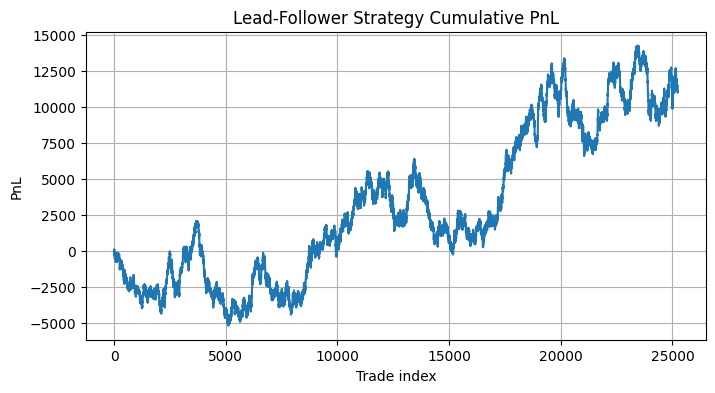

In [11]:
# Build pivot of mid prices
pivot = prices_os.pivot_table(index=['day','timestamp'], columns='product', values='mid_price')
pivot = pivot.sort_index()

# Compute correlation matrix and simple cross-correlation lag to select a pair
corr = pivot.corr()
# Flatten pairs
pairs = []
cols = corr.columns.tolist()
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        pairs.append((cols[i], cols[j], corr.iloc[i,j]))
pairs_sorted = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)

if len(pairs_sorted) == 0:
    print('Not enough products for pairs test')
else:
    leader, follower, corr_val = pairs_sorted[0]
    print(f"Top pair: {leader} vs {follower} (corr={corr_val:.3f})")
    # Estimate lag via cross-correlation
    s1 = pivot[leader].dropna().values
    s2 = pivot[follower].dropna().values
    # Pad shorter
    L = max(len(s1), len(s2))
    if len(s1) < L: s1 = np.pad(s1, (0,L-len(s1)),'edge')
    if len(s2) < L: s2 = np.pad(s2, (0,L-len(s2)),'edge')
    from scipy import signal
    xcorr = signal.correlate(s2 - np.mean(s2), s1 - np.mean(s1), mode='full')
    lags = np.arange(-len(xcorr)//2 + 1, len(xcorr)//2 + 1)
    peak = np.argmax(np.abs(xcorr))
    lag = peak - (len(xcorr)//2)
    print(f'Estimated lag (positive means leader leads): {lag}')

    # Simple lead-follow strategy:
    # If leader return over last step > 0, go LONG follower at next timestamp; hold for hold_period
    hold_period = 3
    entry_qty = 4
    cash = 0.0
    inventory = 0
    trades_records = []
    # Align times
    index = pivot.index
    leader_series = pivot[leader]
    follower_series = pivot[follower]
    # Ensure we have room to enter and exit (t+1+hold_period must be a valid index)
    for t in range(1, max(1, len(index) - hold_period - 1)):
        # safety: ensure future index exists
        if (t + 1 + hold_period) >= len(index):
            continue
        leader_ret = leader_series.iloc[t] - leader_series.iloc[t-1]
        if np.isnan(leader_ret) or np.isnan(follower_series.iloc[t+1]) or np.isnan(follower_series.iloc[t+1+hold_period]):
            continue
        # direction based on leader
        if leader_ret > 0 and corr_val > 0.2:
            # go long follower
            entry_price = follower_series.iloc[t+1]
            exit_price = follower_series.iloc[t+1+hold_period]
            cash -= entry_price * entry_qty
            cash += exit_price * entry_qty
            trades_records.append({'entry_time': index[t+1], 'exit_time': index[t+1+hold_period], 'pnl': (exit_price - entry_price)*entry_qty})
        elif leader_ret < 0 and corr_val > 0.2:
            # go short follower
            entry_price = follower_series.iloc[t+1]
            exit_price = follower_series.iloc[t+1+hold_period]
            cash += entry_price * entry_qty
            cash -= exit_price * entry_qty
            trades_records.append({'entry_time': index[t+1], 'exit_time': index[t+1+hold_period], 'pnl': (entry_price - exit_price)*entry_qty})
    total_pnl = cash
    trades_df_summary = pd.DataFrame(trades_records)
    print(f"Lead-Follower strategy: trades={len(trades_records)}, total_pnl={total_pnl:.2f}")
    if len(trades_df_summary)>0:
        print(trades_df_summary['pnl'].describe())

    # Plot cumulative PnL
    if len(trades_df_summary)>0:
        trades_df_summary['cum_pnl'] = trades_df_summary['pnl'].cumsum()
        plt.figure(figsize=(8,4))
        plt.plot(trades_df_summary['cum_pnl'].values)
        plt.title('Lead-Follower Strategy Cumulative PnL')
        plt.xlabel('Trade index')
        plt.ylabel('PnL')
        plt.grid(True)
        plt.show()

## Comparison and Next Steps

This section summarizes the naive backtests. If you'd like, I can:

- Run the notebook now and return the results.
- Improve the market-maker model (add order placement logic, execution probability, inventory control).
- Improve the pairs strategy (cointegration tests, dynamic hedge ratios, trade sizing, transaction costs).

Tell me which you'd like next.